In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import seaborn as sns
pd.set_option('display.max_rows',None)
from pathlib import Path

In [2]:
data_path = Path('data')
df_o = pd.read_excel(data_path / 'survey_all_responses_ptbr.xlsx')

df = df_o[:]

df.columns = df.columns.str.strip()
df.columns = df.columns.str.replace('\n', '', regex=True)

print(len(df))

#print(df.columns.tolist())

95


In [3]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())


df = df[~(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'] == 'Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software')]
#df = df[~(df['Você costuma utilizar ferramentas de segurança automatizadas em seu dia a dia?'] == 'Não costumo utilizar')]

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].unique())
print(df.shape)

['Nunca tive experiência direta e nem indireta com segurança no processo de desenvolvimento de software'
 'Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
['Meu grupo/equipe de desenvolvimento trabalha (ou trabalhou) com segurança, mas não estou diretamente envolvido em nenhuma tarefa.'
 'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.']
(83, 102)


In [4]:
df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()]

,Carimbo de data/hora,"Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.",Qual é a sua idade?,Em qual estado do Brasil você mora atualmente?,Qual é o seu gênero?,Qual é o seu nível de educação formal concluída?,Qual seu modelo de trabalho?,Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?,"Por favor, indique a senioridade da posição que ocupa.",Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?,...,Em quais fases do ciclo de desenvolvimento de software você costuma utilizar as ferramentas de segurança automatizadas selecionadas na pergunta anterior? (Selecione todas as opções que se aplicam),Quais recomendações você daria para um desenvolvedor sobre a adoção de ferramentas de segurança para seus projetos?,Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam),Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam),"Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email.","Quais são as razões pelas quais você opta por não utilizar ferramentas automatizadas de segurança de software? Por favor, descreva brevemente sobre.",Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?,"Se você respondeu ""Sim"" ou ""Talvez"" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque ""Nenhuma"" se respondeu ""Não"".","Caso você queira receber os resultados desse estudo e participar de uma futura entrevista sobre Práticas de Segurança de Software, por favor, informe seu Email..1",Marque a imagem em que aparece um filhote de cachorro:


In [5]:
print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

df = df.drop(df[df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna()].index, axis=0)

print(df['Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'].isna().sum())

0
0


In [6]:
df['Qual é o seu nível de educação formal concluída?'].unique()

array(['Mestrado', 'Estudante de Doutorado', 'Ensino Superior',
       'Doutorado', 'Especialização', 'Ensino Médio',
       'Estudante de Mestrado'], dtype=object)

In [7]:
df.isna().sum()

Carimbo de data/hora                                                                                                                                                                                                                                                                                                                                                                                                                                            0
Após ter recebido esclarecimentos sobre a natureza da pesquisa, seus objetivos e métodos, eu declaro que sou maior de 18 anos e aceito participar por meio do formulário de participação, conforme as disposições da Lei Geral de Proteção de Dados (Lei nº 13.709/2018).Em caso de resposta negativa, o formulário será encerrado, garantindo assim o respeito à autonomia e privacidade dos participantes, conforme estabelecido pela legislação vigente.     0
Qual é a sua idade?                                                                                 

In [8]:

df.shape

(83, 102)

In [9]:
direct_experience_col = (
    'Você tem (ou teve) alguma experiência de trabalho relacionada à segurança de software no processo de desenvolvimento de software?'
)

years_experience_dev_col = (
    'Quantos anos de experiência você tem em funções relacionadas ao desenvolvimento de software ou TI?'
)

years_experience_sec_col = (
    'Quantos anos de experiência você tem em funções relacionadas a Segurança de Software?'
)

education_level_col = 'Qual é o seu nível de educação formal concluída?'

seniority_col = 'Por favor, indique a senioridade da posição que ocupa.'

specialist_role_col = (
    'Qual papel que melhor descreve suas atividades atuais em projetos de desenvolvimento de software?'
)

certification_col = (
    'Você possui alguma certificação na área de segurança da informação? Se sim, quais são elas?'
)

has_experience_answer = (
    'Eu já trabalhei (ou trabalho) com segurança no processo de desenvolvimento de software.'
)

# Answer groups
specialist_answers = [
    "Cryptographer",
    "Penetration tester",
    "DevOps engineer",
    "Privacy engineer",
    "Security engineer",
]

no_certification_answers = ["Não possui nenhuma certificação"]


In [10]:
df_direct_experience = df[df[direct_experience_col] == has_experience_answer]
df_indirect_experience = df[df[direct_experience_col] != has_experience_answer]

In [11]:
education_level_map = {
    'Ensino Médio': 1,
    'Ensino Superior': 2,
    'Especialização': 3,
    'Estudante de Mestrado': 4,
    'Mestrado': 5,
    'Estudante de Doutorado': 6,
    'Doutorado': 7
}

seniority_map = {
    'Estagiário': 1,
    'Júnior (até 5 anos)': 2,
    'Pleno (6 a 9 anos)': 3,
    'Sênior (10+ anos)': 4
}

years_experience_dev_map = {
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 5 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}

years_experience_sec_map = {
    'Nenhuma': 0,
    'Menos de 1 ano': 1,
    'Entre 1 e 3 anos': 2,
    'Entre 4 e 6 anos': 3,
    'Entre 7 e 14 anos': 4,
    'Mais de 15 anos': 5
}


def direct_exp_specialist_interaction(row):
    if row['especialista'] and row['experiencia_direta']:
        return 3
    elif row['experiencia_direta'] and not row['especialista']:
        return 2
    else:
        return 1


def direct_exp_specialist_relation(row):
    return (row['especialista'] + row['experiencia_direta']) / 2


df[years_experience_dev_col] = df[years_experience_dev_col].map(
    years_experience_dev_map
)

df[seniority_col] = df[seniority_col].map(seniority_map)

df[years_experience_sec_col] = df[years_experience_sec_col].map(
    years_experience_sec_map
)


In [12]:
df['especialista'] = df[specialist_role_col].apply(
    lambda x: 1 if x in specialist_answers else 0
)

df['experiencia_direta'] = df[direct_experience_col].apply(
    lambda x: 1 if x == has_experience_answer else 0
)

df['certification'] = df[certification_col].apply(
    lambda x: 0 if x in no_certification_answers else 1
)

df[education_level_col] = df[education_level_col].map(
    education_level_map
)

df['direct_exp_specialist_interaction'] = df.apply(
    direct_exp_specialist_interaction, axis=1
)

df['direct_exp_specialist_relation'] = df.apply(
    direct_exp_specialist_relation, axis=1
)


In [13]:
education_level = df[education_level_col]
years_experience_dev = df[years_experience_dev_col]
years_experience_sec = df[years_experience_sec_col]
seniority = df[seniority_col]

direct_exp_specialist_interaction_col = df['direct_exp_specialist_interaction']
direct_exp_specialist_relation_col = df['direct_exp_specialist_relation']

certification = df['certification']


In [14]:
df.shape

(83, 107)

**Q28**

In [15]:
import re

# Definition of direct, indirect, large and small responses
direct_answer = 1
indirect_answer = 0

small_company_answers = [
    "Até 9 funcionários",
    "De 10 a 49 funcionários",
    "De 50 a 99 funcionários"
]

large_company_answers = [
    "De 100 a 499 funcionários",
    "De 500 a 999 funcionários",
    "Mais de 1000 funcionários"
]

specialist_answer = 1
non_specialist_answer = 0

# Correct column names
direct_experience_col = 'experiencia_direta'
company_size_col = 'Qual o tamanho da empresa para a qual você trabalha atualmente?'
specialist_col = 'especialista'
systems_col = 'Quais são os tipos de sistemas que você trabalha?'

# Filter direct and indirect responses
direct = df[df[direct_experience_col] == direct_answer].copy()
indirect = df[df[direct_experience_col] == indirect_answer].copy()

# Filter large and small companies
large_companies = df[df[company_size_col].isin(large_company_answers)].copy()
small_companies = df[df[company_size_col].isin(small_company_answers)].copy()

specialists = df[df[specialist_col] == specialist_answer].copy()
non_specialists = df[df[specialist_col] == non_specialist_answer].copy()


In [16]:
print("Number of participants in the Direct Experience group:", len(direct))
print("Number of participants in the Indirect Experience group:", len(indirect))
print("--"*35)

print("Number of participants in the Large Companies group:", len(large_companies))
print("Number of participants in the Small Companies group:", len(small_companies))
print("--"*35)

print("Number of participants in the Specialists group:", len(specialists))
print("Number of participants in the Non-Specialists group:",
      len(non_specialists))
print("--"*35)

print(f"Percentage of participants in the Large group: {len(large_companies)/88:.1f}")
print(f"Percentage of participants in the Small group: {len(small_companies)/88:.1f}")


Number of participants in the Direct Experience group: 62
Number of participants in the Indirect Experience group: 21
----------------------------------------------------------------------
Number of participants in the Large Companies group: 65
Number of participants in the Small Companies group: 16
----------------------------------------------------------------------
Number of participants in the Specialists group: 26
Number of participants in the Non-Specialists group: 57
----------------------------------------------------------------------
Percentage of participants in the Large group: 0.7
Percentage of participants in the Small group: 0.2


In [17]:
challenges_col = "Quais são os principais desafios que você enfrenta ao automatizar ferramentas de segurança? (Selecione todas as opções que se aplicam)"

In [18]:
challenge_options = [
    'Custo',
    'Curva de aprendizado',
    'Integração com outras ferramentas',
    'Performance do sistema',
    'Falsos positivos',
    'Falsos negativos',
    'Manutenção das ferramentas automatizadas',
    'Escalabilidade',
    'Falta de suporte técnico',
    'Compatibilidade com diferentes ambientes de desenvolvimento',
    'Necessidade de atualizações frequentes',
    'Aderência a normas e compliance',
    'Falta de visibilidade ou relatórios inadequados',
    'Outros'
]


In [19]:
def count_responses(group_df):
    counts = {op: 0 for op in challenge_options}

    for _, row in group_df.iterrows():
        resp = row[challenges_col]
        if pd.isna(resp):
            continue

        choices = [op.strip() for op in resp.split(",")]

        for op in choices:
            if op in counts:
                counts[op] += 1
            else:
                counts["Outros"] += 1

    return pd.DataFrame.from_dict(counts, orient="index", columns=["Total"])


In [20]:
df_direct = count_responses(direct)
df_indirect = count_responses(indirect)

df_large = count_responses(large_companies)
df_small = count_responses(small_companies)

df_specialists = count_responses(specialists)
df_non_specialists = count_responses(non_specialists)


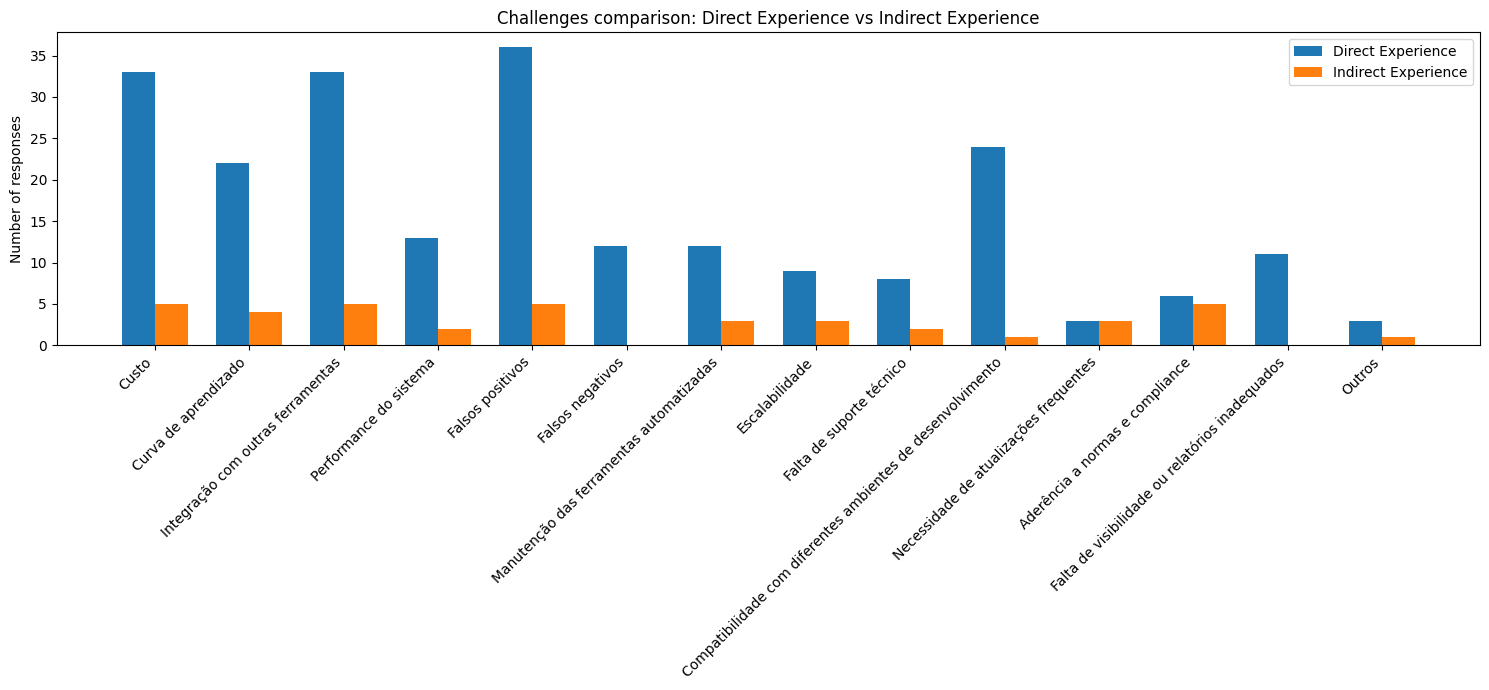

In [21]:
def comparison_chart(df1, df2, name1, name2):
    plt.figure(figsize=(15, 7))

    x = np.arange(len(df1.index))
    width = 0.35

    plt.bar(x - width/2, df1["Total"], width=width, label=name1)
    plt.bar(x + width/2, df2["Total"], width=width, label=name2)

    plt.xticks(x, df1.index, rotation=45, ha='right')
    plt.ylabel("Number of responses")
    plt.title(f"Challenges comparison: {name1} vs {name2}")
    plt.legend()
    plt.tight_layout()
    plt.show()

# Direct vs Indirect
comparison_chart(df_direct, df_indirect, "Direct Experience", "Indirect Experience")


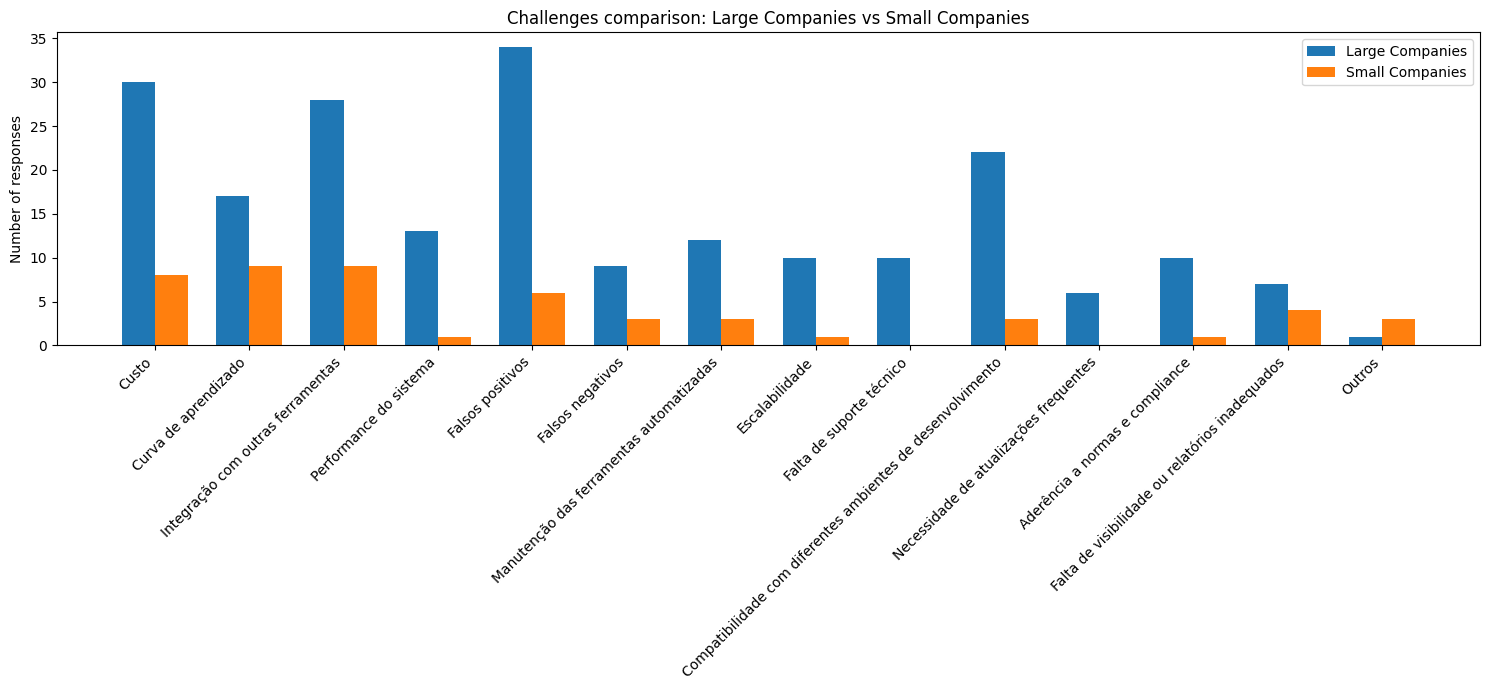

In [22]:
comparison_chart(df_large, df_small, "Large Companies", "Small Companies")

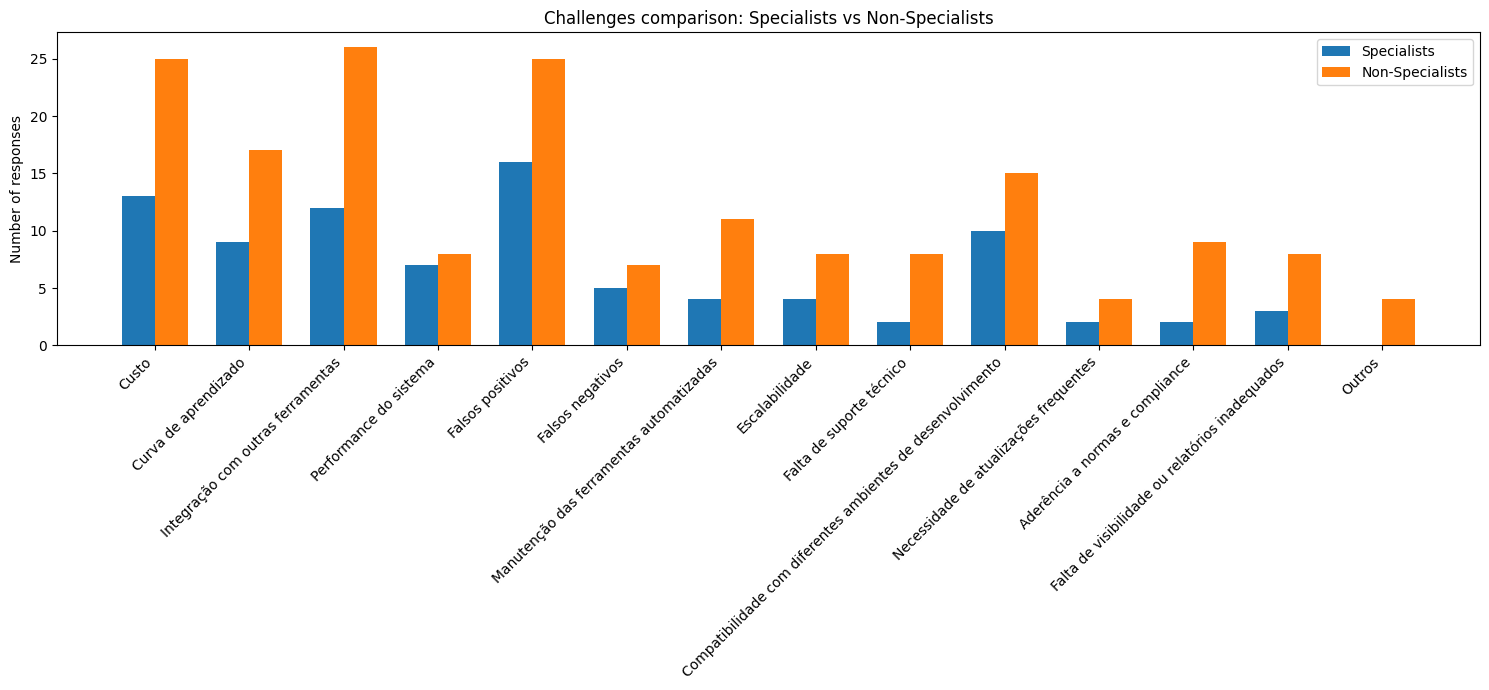

In [23]:
comparison_chart(df_specialists, df_non_specialists, "Specialists", "Non-Specialists")

**Q29**

In [24]:
improvements_col = 'Quais melhorias você gostaria de ver nas ferramentas de segurança automatizadas que utiliza atualmente? (Selecione todas as opções que se aplicam)'

In [25]:
improvements_options = [
    'Aumentar a abrangência das ameaças',
    'Menos falsos positivos',
    'Melhor integração com o CI/CD',
    'Melhor documentação e suporte',
    'Facilidade de uso',
    'Melhor usabilidade da interface',
    'Redução do tempo de análise',
    'Melhor compatibilidade com diferentes ambientes de desenvolvimento',
    'Relatórios mais detalhados e customizáveis'
]

In [26]:
col = df[improvements_col].dropna()

In [27]:
exploded_answers = (
    col.str.split(',')
       .explode()
       .str.strip()
)

In [28]:
count = exploded_answers.value_counts()
print(exploded_answers.unique())

['Menos falsos positivos' 'Melhor integração com o CI/CD'
 'Melhor compatibilidade com diferentes ambientes de desenvolvimento'
 'Facilidade de uso' 'Melhor documentação e suporte'
 'Redução do tempo de análise' 'Melhor usabilidade da interface'
 'Aumentar a abrangência das ameaças'
 'Relatórios mais detalhados e customizáveis'
 'Feedback e aprendizado contínuo' 'Redução no custo' 'nao posso opninar'
 'Formatação de findings em padrão estipulado como o SARIF.'
 'Customizar regras' 'Classificação e Priorização baseado em Risco'
 'Funil de Classificação.']


In [29]:
tabel = count.reset_index()
tabel.columns = ["Resposta", "Frequência"]

print("\n=== Frequency answers tabel===\n")
print(tabel)


=== Frequency answers tabel===

                                             Resposta  Frequência
0                              Menos falsos positivos          48
1                       Melhor integração com o CI/CD          41
2   Melhor compatibilidade com diferentes ambiente...          27
3                       Melhor documentação e suporte          26
4                                   Facilidade de uso          23
5                  Aumentar a abrangência das ameaças          21
6                         Redução do tempo de análise          20
7          Relatórios mais detalhados e customizáveis          18
8                     Melhor usabilidade da interface          13
9                     Feedback e aprendizado contínuo           1
10                                   Redução no custo           1
11                                  nao posso opninar           1
12  Formatação de findings em padrão estipulado co...           1
13                                  Customi

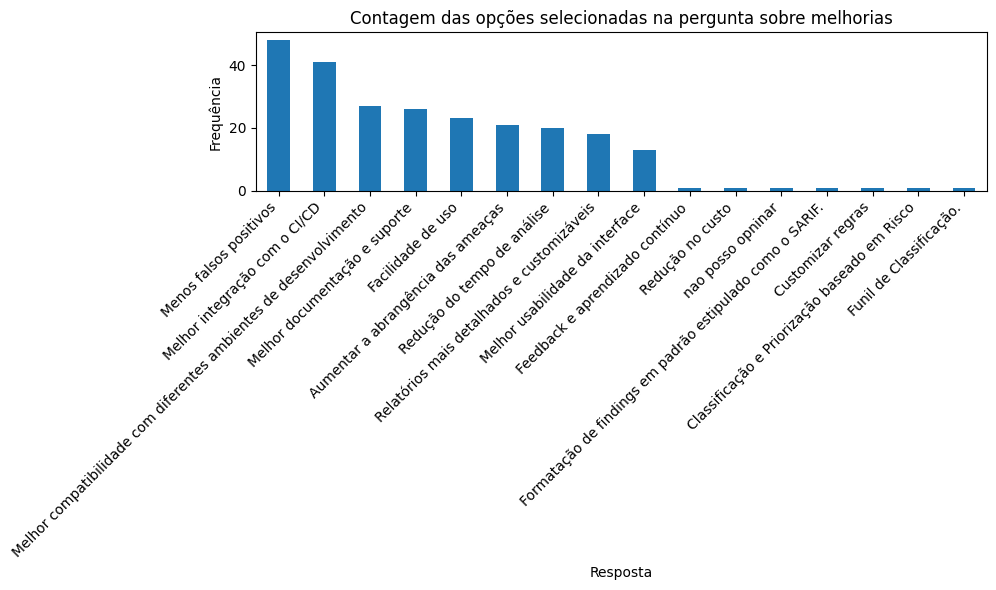

In [30]:
plt.figure(figsize=(10, 6))
count.plot(kind='bar')
plt.xlabel("Resposta")
plt.ylabel("Frequência")
plt.title("Contagem das opções selecionadas na pergunta sobre melhorias")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

**Q32**

In [31]:
future_col = 'Você considera utilizar ferramentas automatizadas de segurança de software em seus projetos no futuro?'

In [32]:
valid_options = ['Sim', 'Não', 'Talvez']

In [33]:
answers = (
    df[future_col]
    .dropna()
    .astype(str)
    .str.strip()
)


In [34]:
df = df[df[future_col].isin(valid_options)]

In [35]:
def contar_ferramentas_por_grupo(df, grupo_resposta):
    """ Retorna a contagem de ferramentas para quem respondeu Sim/Não/Talvez """

    subset = df[df[future_col] == grupo_resposta][col_fer_future].dropna()

    # Explode lista de respostas
    respostas = (
        subset.str.split(',')
              .explode()
              .str.strip()
    )

    # Contagem incluindo ferramentas fora da lista oficial
    return respostas.value_counts()

In [36]:
count = answers.value_counts().reindex(valid_options, fill_value=0)

In [37]:
tabel = count.reset_index()
tabel.columns = ["Resposta", "Frequência"]

print("\n=== Answers Frequency Tabels ===\n")
print(tabel)


=== Answers Frequency Tabels ===

  Resposta  Frequência
0      Sim           6
1      Não           2
2   Talvez           6


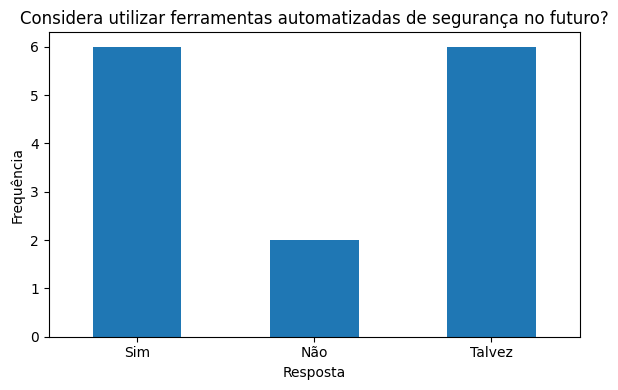

In [38]:
plt.figure(figsize=(6, 4))
count.plot(kind='bar')
plt.xlabel("Resposta")
plt.ylabel("Frequência")
plt.title("Considera utilizar ferramentas automatizadas de segurança no futuro?")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Q33**

In [39]:
col_fer_futuro = 'Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".'

In [40]:
options_fer_future = [
    'Nenhuma', 'Dependabot', 'PHP Security Checker', 'Snyk', 'Clair', 'Blackduck', 'Retire.JS', 'SRC:CLR', 'Anchore', 'Node Security Platform',
    'Trivy', 'Sonatype', 'Whitesource', 'CodeQL', 'CheckStyle', 'Coverity', 'SonarQube', 'Bandit', 'PHPStan', 'LGTM',
    'Brakeman', 'Qark', 'ESLint Security', 'Dart Analyzer', 'Checkmarx', 'DevSkim', 'CFN NAG', 'SpotBugs', 'Chef', 'Ansible',
    'Terraform', 'Puppet', 'Phan', 'Seccomp', 'CloudCustodian', 'Turbot', 'Bane', 'Ansible-Lint', 'Blackbox', 'Puppet-Lint',
    'InSpec', 'Kube Audit', 'Foodcritic', 'Cookstyle', 'conftest', 'Pinterest Knox', 'GitLeaks', 'CyberArk Conjur', 'ThoughtWorks Talisman', 'Berglas',
    'Docker Secrets', 'Trufflehog', 'AppScan', 'Fortify'

]

print(len(options_fer_future))

54


In [41]:
col_f = df[col_fer_futuro].dropna()

In [42]:
exploded_answers = (
    col_f.str.split(',')
       .explode()
       .str.strip()
)

In [43]:
count = exploded_answers.value_counts()

In [44]:
tabel = count.reset_index()
tabel.cols = ["Tool", "Frequency"]

print("\n=== FREQUENCY TABLE FOR FUTURE TOOLS ===\n")
print(tabel)


=== FREQUENCY TABLE FOR FUTURE TOOLS ===

   Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".  \
0                                           Retire.JS                                                                                               
1                                           SonarQube                                                                                               
2                                            Blackbox                                                                                               
3                                            GitLeaks                                                                                               
4                                      CloudCustodian                                                                                               
5                                PHP Security Checker          

C:\Users\reset\AppData\Local\Temp\ipykernel_18380\4037409323.py:2: UserWarning: Pandas doesn't allow columns to be created via a new attribute name - see https://pandas.pydata.org/pandas-docs/stable/indexing.html#attribute-access
  tabel.cols = ["Tool", "Frequency"]


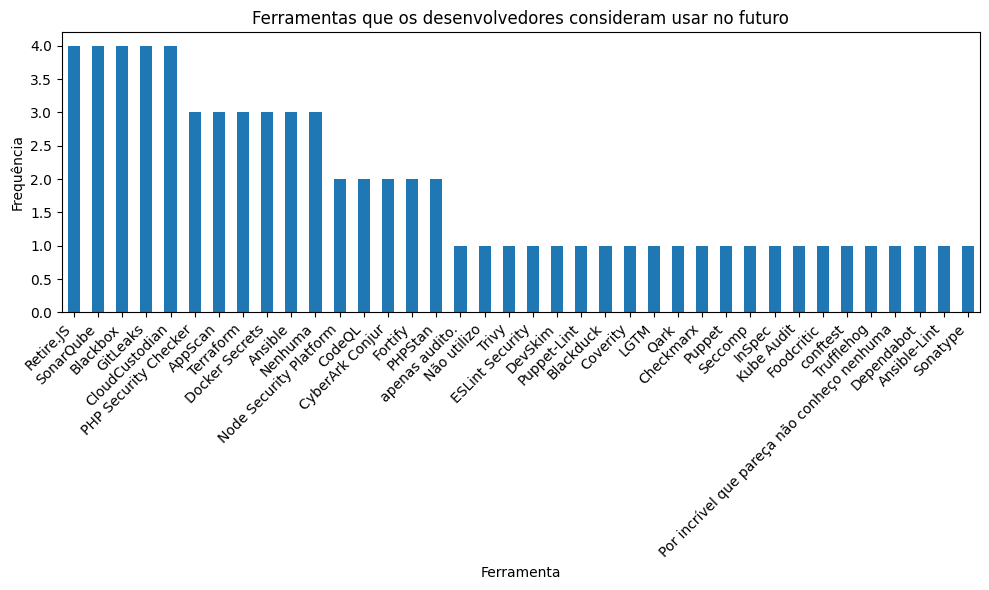

In [45]:
plt.figure(figsize=(10, 6))
count.plot(kind='bar')
plt.xlabel("Ferramenta")
plt.ylabel("Frequência")
plt.title("Ferramentas que os desenvolvedores consideram usar no futuro")
plt.xticks(rotation=45, ha='right')
plt.tight_layout()
plt.show()

In [46]:
df[future_col] = (
    df[future_col]
      .astype(str)
      .str.strip()
      .str.capitalize()
)

# Mantém apenas respostas válidas
df = df[df[future_col].isin(valid_options)]


# -----------------------------
# FUNÇÃO PARA CONTAGEM
# -----------------------------

def contar_ferramentas_por_grupo(df, grupo_resposta):
    # Filtra os participantes daquele grupo
    subset = df[df[future_col] == grupo_resposta][col_fer_futuro].dropna()

    # Corrige múltiplos separadores
    subset = subset.str.replace("; ", ",").str.replace(";", ",")

    # Explode corretamente
    answers = (
        subset
        .astype(str)
        .str.split(",")      # separa por vírgula
        .explode()           # transforma lista em linhas
        .str.strip()         # remove espaços
        .replace("", pd.NA)  # remove itens vazios
        .dropna()
    )

    # Agora conta TUDO sem filtrar por opcoes_fer_futuro
    return answers.value_counts()


# -----------------------------
# CONTAGEM POR GRUPO
# -----------------------------

count_yes = contar_ferramentas_por_grupo(df, "Sim")
count_not = contar_ferramentas_por_grupo(df, "Não")
count_maybe = contar_ferramentas_por_grupo(df, "Talvez")


# -----------------------------
# EXIBIÇÃO DAS TABELAS
# -----------------------------

print("\n=== Ferramentas citadas por quem respondeu 'Sim' ===\n")
print(count_yes.reset_index().rename(columns={'index':'Tool', 'count':'Frequency'}))

print("\n=== Ferramentas citadas por quem respondeu 'Não' ===\n")
print(count_not.reset_index().rename(columns={'index':'Tool', 'count':'Frequency'}))

print("\n=== Ferramentas citadas por quem respondeu 'Talvez' ===\n")
print(count_maybe.reset_index().rename(columns={'index':'Tool', 'count':'Frequency'}))


=== Ferramentas citadas por quem respondeu 'Sim' ===

   Se você respondeu "Sim" ou "Talvez" à pergunta anterior, por favor, indique quais ferramentas utilizaria. Marque "Nenhuma" se respondeu "Não".  \
0                                PHP Security Checker                                                                                               
1                                           Retire.JS                                                                                               
2                                      Docker Secrets                                                                                               
3                                            GitLeaks                                                                                               
4                                      CloudCustodian                                                                                               
5                                           Terrafo

In [47]:
df[col_fer_futuro].unique()

array(['PHP Security Checker, Retire.JS, SonarQube',
       'Retire.JS, GitLeaks, AppScan', 'SonarQube, Blackbox, AppScan',
       'Não utilizo, apenas audito.',
       'Ansible, Terraform, CloudCustodian, GitLeaks, Docker Secrets',
       'PHP Security Checker, Retire.JS, Node Security Platform, Trivy, CodeQL, PHPStan, ESLint Security, DevSkim, Terraform, CloudCustodian, Puppet-Lint, GitLeaks, CyberArk Conjur, Docker Secrets, Fortify',
       'Nenhuma',
       'PHP Security Checker, Blackduck, Retire.JS, Node Security Platform, CodeQL, Coverity, SonarQube, PHPStan, LGTM, Qark, Checkmarx, Ansible, Terraform, Puppet, Seccomp, CloudCustodian, Blackbox, InSpec, Kube Audit, Foodcritic, conftest, GitLeaks, CyberArk Conjur, Docker Secrets, Trufflehog, AppScan, Fortify',
       'Por incrível que pareça não conheço nenhuma',
       'Dependabot, SonarQube, CloudCustodian, Ansible-Lint, Blackbox',
       'Sonatype, Blackbox', 'Ansible'], dtype=object)